In [ ]:

# Cell 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:

# Cell 2: Upload the dataset

from google.colab import files

uploaded = files.upload()


Saving maternal+health+risk.zip to maternal+health+risk.zip


In [ ]:

print("Uploaded files:", list(uploaded.keys()))


Uploaded files: ['maternal+health+risk.zip']


In [ ]:

import zipfile
import io
import os

zip_name = "maternal+health+risk.zip"

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), "r") as zip_ref:
    zip_ref.extractall("/content/maternal_data")

print("ZIP extracted successfully!")

for root, dirs, files_list in os.walk("/content/maternal_data"):
    for name in files_list:
        print(os.path.join(root, name))


ZIP extracted successfully!
/content/maternal_data/Maternal Health Risk Data Set.csv


In [ ]:

import glob
import pandas as pd

csv_files = glob.glob(
    "/content/maternal_data/**/*.csv",
    recursive=True
)

if not csv_files:
    print("No CSV file found inside the ZIP.")
else:
    print("CSV files found:", csv_files)

    df = pd.read_csv(csv_files[0])

    print("\nDataset shape:", df.shape)
    print("\nColumn names:", df.columns.tolist())
    print("\nFirst five records:")
    display(df.head())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nRisk-level distribution:")
    print(df["RiskLevel"].value_counts())


CSV files found: ['/content/maternal_data/Maternal Health Risk Data Set.csv']

Dataset shape: (1014, 7)

Column names: ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']

First five records:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk



Missing values:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

Risk-level distribution:
RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


In [ ]:

# Cell 4: Separate features and target

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Input features and target
X = df.drop(columns=["RiskLevel"]).astype("float32")
y = df["RiskLevel"].str.strip().str.lower()

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Input features:", X.columns.tolist())
print("Class mapping:")

for index, label in enumerate(label_encoder.classes_):
    print(f"{label} -> {index}")

# Split: 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Fit scaler only on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_val_scaled = scaler.transform(X_val).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

print("\nTraining shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nPreprocessing completed successfully!")


Input features: ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']
Class mapping:
high risk -> 0
low risk -> 1
mid risk -> 2

Training shape: (709, 6)
Validation shape: (152, 6)
Testing shape: (153, 6)

Preprocessing completed successfully!


In [ ]:

# Cell 5: Verify the split

print("Training records:", len(X_train_scaled))
print("Validation records:", len(X_val_scaled))
print("Testing records:", len(X_test_scaled))

print("\nTraining class distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts())

print("\nValidation class distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_val)
).value_counts())

print("\nTest class distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_test)
).value_counts())


Training records: 709
Validation records: 152
Testing records: 153

Training class distribution:
low risk     284
mid risk     235
high risk    190
Name: count, dtype: int64

Validation class distribution:
low risk     61
mid risk     50
high risk    41
Name: count, dtype: int64

Test class distribution:
low risk     61
mid risk     51
high risk    41
Name: count, dtype: int64


In [ ]:

# Cell 6: Build the Autoencoder

from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD

# Encoder
input_layer = Input(shape=(X_train_scaled.shape[1],), name="input")
encoded = Dense(4, activation="relu", name="encoder_hidden")(input_layer)
latent = Dense(2, activation="linear", name="latent_space")(encoded)

# Decoder
decoded = Dense(4, activation="relu", name="decoder_hidden")(latent)
reconstruction = Dense(6, activation="linear", name="reconstruction")(decoded)

# Complete autoencoder
autoencoder = Model(input_layer, reconstruction, name="Maternal_Autoencoder")

# Separate encoder for extracting latent features
encoder = Model(input_layer, latent, name="Maternal_Encoder")

# Required optimizer: Stochastic Gradient Descent
autoencoder.compile(
    optimizer=SGD(learning_rate=0.01),
    loss="mse"
)

autoencoder.summary()
print("\nEncoder output shape:", encoder.output_shape)


Model: "Maternal_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 4)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 6)              │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80 (320.00 B)

 Trainable params: 80 (320.00 B)

 Non-trainable params: 0 (0.00 B)


Encoder output shape: (None, 2)


In [ ]:

# Cell 7: Train the Autoencoder

from tensorflow.keras.callbacks import EarlyStopping

early_stop_ae = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history_ae = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    validation_data=(X_val_scaled, X_val_scaled),
    epochs=300,
    batch_size=32,
    callbacks=[early_stop_ae],
    verbose=1
)

print("\nAutoencoder training completed!")


Epoch 1/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 1.1804 - val_loss: 1.0455
Epoch 2/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.1182 - val_loss: 1.0033
Epoch 3/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.0781 - val_loss: 0.9742
Epoch 4/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0495 - val_loss: 0.9529
Epoch 5/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0285 - val_loss: 0.9376
Epoch 6/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.0129 - val_loss: 0.9261
Epoch 7/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0012 - val_loss: 0.9177
Epoch 8/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.9922 - val_loss: 0.9108
Epoch 9/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9845 - val_loss: 0.9048
Epoch 10/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9774 - val_loss: 0.8992
Epoch 11/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9705 - val_loss: 0.8938
Epoch 12/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 

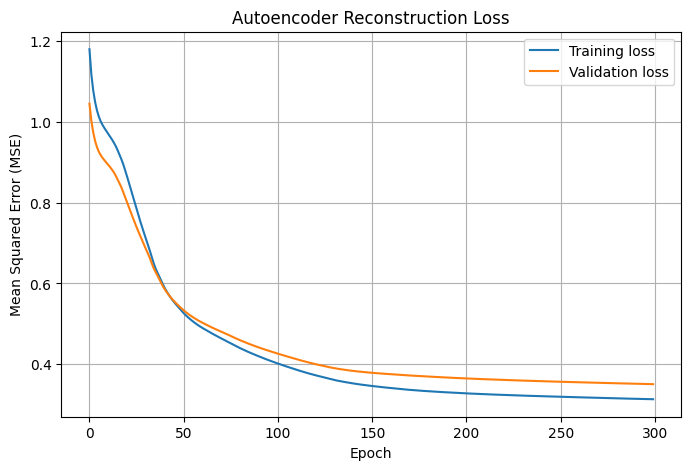

In [ ]:

# Cell 8: Reconstruction loss plot

plt.figure(figsize=(8, 5))
plt.plot(history_ae.history["loss"], label="Training loss")
plt.plot(history_ae.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Autoencoder Reconstruction Loss")
plt.legend()
plt.grid(True)
plt.show()


Test reconstruction MSE: 0.3704
Mean per-record reconstruction error: 0.3704
Standard deviation of reconstruction error: 0.4735


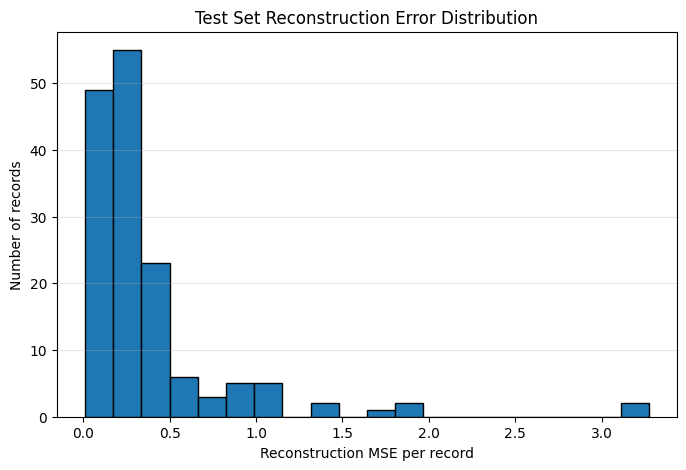

In [ ]:

# Cell 9: Evaluate reconstruction performance

from sklearn.metrics import mean_squared_error

# Reconstruct the held-out test data
X_test_reconstructed = autoencoder.predict(
    X_test_scaled, verbose=0
)

test_mse = mean_squared_error(
    X_test_scaled.flatten(),
    X_test_reconstructed.flatten()
)

# Per-record reconstruction error
reconstruction_errors = np.mean(
    np.square(X_test_scaled - X_test_reconstructed),
    axis=1
)

print(f"Test reconstruction MSE: {test_mse:.4f}")
print(
    "Mean per-record reconstruction error:",
    f"{reconstruction_errors.mean():.4f}"
)
print(
    "Standard deviation of reconstruction error:",
    f"{reconstruction_errors.std():.4f}"
)

plt.figure(figsize=(8, 5))
plt.hist(reconstruction_errors, bins=20, edgecolor="black")
plt.xlabel("Reconstruction MSE per record")
plt.ylabel("Number of records")
plt.title("Test Set Reconstruction Error Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()


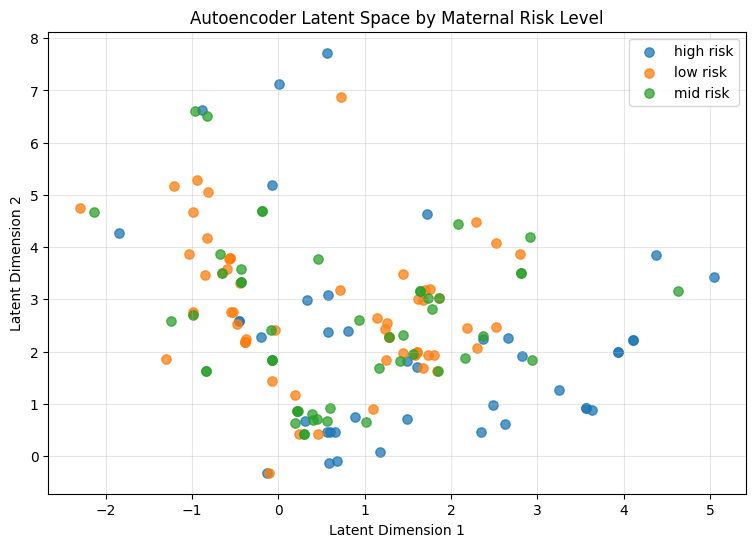

Latent test shape: (153, 2)


In [ ]:

# Cell 10: Extract and visualize latent features

latent_test = encoder.predict(X_test_scaled, verbose=0)

plt.figure(figsize=(9, 6))

for class_id, class_name in enumerate(label_encoder.classes_):
    mask = y_test == class_id

    plt.scatter(
        latent_test[mask, 0],
        latent_test[mask, 1],
        label=class_name,
        alpha=0.75,
        s=45
    )

plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("Autoencoder Latent Space by Maternal Risk Level")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Latent test shape:", latent_test.shape)


In [ ]:

# Cell 11: Extract latent features for all data splits

Z_train = encoder.predict(X_train_scaled, verbose=0)
Z_val = encoder.predict(X_val_scaled, verbose=0)
Z_test = encoder.predict(X_test_scaled, verbose=0)

print("Encoded training data:", Z_train.shape)
print("Encoded validation data:", Z_val.shape)
print("Encoded testing data:", Z_test.shape)


Encoded training data: (709, 2)
Encoded validation data: (152, 2)
Encoded testing data: (153, 2)


In [ ]:

# Cell 12: Build and compile the MLP classifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import EarlyStopping

num_classes = len(label_encoder.classes_)

mlp = Sequential([
    Input(shape=(Z_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(num_classes, activation="softmax")
], name="Maternal_Risk_MLP")

mlp.compile(
    optimizer=SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mlp.summary()


Model: "Maternal_Risk_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211 (844.00 B)

 Trainable params: 211 (844.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Cell 13: Train the MLP using SGD

early_stop_mlp = EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history_mlp = mlp.fit(
    Z_train, y_train,
    validation_data=(Z_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=[early_stop_mlp],
    verbose=1
)

print("\nMLP training completed!")


Epoch 1/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.4006 - loss: 1.1016 - val_accuracy: 0.4145 - val_loss: 1.0742
Epoch 2/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4048 - loss: 1.0694 - val_accuracy: 0.4211 - val_loss: 1.0524
Epoch 3/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4062 - loss: 1.0576 - val_accuracy: 0.4013 - val_loss: 1.0389
Epoch 4/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4429 - loss: 1.0491 - val_accuracy: 0.4737 - val_loss: 1.0274
Epoch 5/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4866 - loss: 1.0417 - val_accuracy: 0.4671 - val_loss: 1.0175
Epoch 6/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4979 - loss: 1.0348 - val_accuracy: 0.4803 - val_loss: 1.0086
Epoch 7/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5148 - loss: 1.0282 - val_accuracy: 0.5066 - val_loss: 0.9998
Epoch 8/300
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5374 - loss: 1.0216 - val_accuracy: 0.5395 

Test Accuracy: 0.5163
Macro F1-score: 0.5077
Weighted F1-score: 0.5094

Classification Report:
              precision    recall  f1-score   support

   high risk       0.85      0.41      0.56        41
    low risk       0.49      0.72      0.58        61
    mid risk       0.42      0.35      0.38        51

    accuracy                           0.52       153
   macro avg       0.59      0.50      0.51       153
weighted avg       0.56      0.52      0.51       153



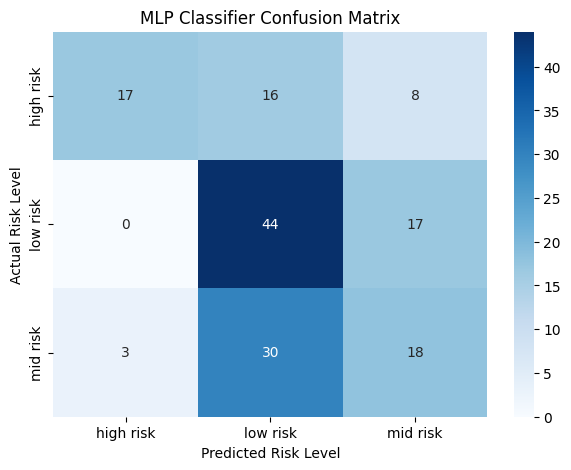

In [ ]:

# Cell 14: Test set evaluation

y_prob = mlp.predict(Z_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(
    "Macro F1-score:",
    round(f1_score(y_test, y_pred, average="macro"), 4)
)
print(
    "Weighted F1-score:",
    round(f1_score(y_test, y_pred, average="weighted"), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Risk Level")
plt.ylabel("Actual Risk Level")
plt.title("MLP Classifier Confusion Matrix")
plt.show()


In [ ]:

# Cell 15: Majority-class baseline comparison

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_scaled, y_train)

baseline_pred = baseline.predict(X_test_scaled)

results = pd.DataFrame({
    "Model": [
        "Majority-Class Baseline",
        "Autoencoder + MLP (SGD)"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Macro F1": [
        f1_score(y_test, baseline_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ],
    "Weighted F1": [
        f1_score(y_test, baseline_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0)
    ]
})

display(results.round(4))


,Model,Accuracy,Macro F1,Weighted F1
0,Majority-Class Baseline,0.3987,0.1900,0.2273
1,Autoencoder + MLP (SGD),0.5163,0.5077,0.5094


In [ ]:

# Cell 17: Create folders for project outputs

import os

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

# Save autoencoder reconstruction-loss plot
plt.figure(figsize=(8, 5))
plt.plot(history_ae.history["loss"], label="Training loss")
plt.plot(history_ae.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder Reconstruction Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "outputs/figures/autoencoder_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Save latent-space plot
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(label_encoder.classes_):
    mask = y_test == class_id
    plt.scatter(
        latent_test[mask, 0],
        latent_test[mask, 1],
        label=class_name,
        alpha=0.75
    )

plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("Maternal Risk Latent Space")
plt.legend()
plt.tight_layout()
plt.savefig(
    "outputs/figures/latent_space.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Save baseline comparison
results.to_csv(
    "outputs/results/model_comparison.csv",
    index=False
)

# Save test classification report
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "outputs/results/classification_report.csv"
)

print("Project output files saved successfully!")


Project output files saved successfully!
